## 1. Dataset Loading and Initial Validation

In this step, I load the accelerometer signal dataset and prepare it for further analysis. I select the required columns (`Sample`, `Value`, and `label`) and perform basic data-quality checks to ensure that the dataset is suitable for signal processing and machine learning.

The following operations are carried out:

1. **Library initialization:** I import the Python libraries required for data handling, numerical computation, visualization, statistical feature extraction, and file management.
2. **File and output configuration:** I define the input dataset path, output directory, window size, class labels, and random seed to ensure reproducibility.
3. **Dataset loading:** I read the required columns from the CSV file to avoid loading unnecessary data.
4. **Data cleaning:** I remove observations with missing values in the required columns and convert the sample coordinates and signal measurements to numeric types.
5. **Data-quality validation:** I check for non-finite numerical values and unexpected class labels.
6. **Initial inspection:** I display the dataset dimensions, class distribution, and first few observations to verify that the data has been loaded correctly.

The `label` column identifies the two classes: **0 — No Leak** and **1 — Orifice Leak**. The `Value` column contains the measured vibration-signal values, while `Sample` represents the sample coordinate provided in the dataset.

In [10]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis
INPUT_CSV = Path("/content/combined_leak_dataset.csv")
OUTPUT_DIR = Path("/content/leak_analysis_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SIZE = 25_600  # Samples per window; justify using sampling rate and signal duration
LABEL_NAMES = {0: "No Leak", 1: "Orifice Leak"}
RANDOM_STATE = 42

if not INPUT_CSV.exists():
    raise FileNotFoundError(
        f"Could not find {INPUT_CSV}. Upload the CSV or update INPUT_CSV."
    )

df = pd.read_csv(INPUT_CSV, usecols=["Sample", "Value", "label"])
required = {"Sample", "Value", "label"}
if not required.issubset(df.columns):
    raise ValueError(f"Input must contain columns: {sorted(required)}")

df = df.dropna(subset=["Sample", "Value", "label"]).copy()
df["Sample"] = pd.to_numeric(df["Sample"], errors="raise")
df["Value"] = pd.to_numeric(df["Value"], errors="raise")
df["label"] = pd.to_numeric(df["label"], errors="raise").astype(int)

if not np.isfinite(df[["Sample", "Value"]].to_numpy()).all():
    raise ValueError("Sample or Value contains non-finite values.")
if not set(df["label"].unique()).issubset(set(LABEL_NAMES)):
    raise ValueError(f"Unexpected labels found: {sorted(df['label'].unique())}")

print(f"Rows: {len(df):,}")
print(f"Columns: {df.columns.tolist()}")
print("\nSamples per label:")
print(df["label"].value_counts().sort_index().rename(index=LABEL_NAMES))
print("\nFirst rows:")
display(df.head())

Rows: 1,826,571
Columns: ['Sample', 'Value', 'label']

Samples per label:
label
No Leak         910673
Orifice Leak    915898
Name: count, dtype: int64

First rows:


,Sample,Value,label
0,0.000000,0.003442,0
1,0.000039,0.001532,0
2,0.000078,0.000284,0
3,0.000117,0.001285,0
4,0.000156,0.001887,0


## 2. Signal Segmentation and Visualization

In this step, I identify continuous segments of the accelerometer signal that share the same class label. I use the `label` column to detect transitions between the no-leak and orifice-leak conditions and assign a unique segment ID to each continuous labelled segment.

For each segment, I calculate the total number of samples, the starting and ending sample coordinates, and the minimum and maximum signal values. I also map the numerical labels to their corresponding class names to make the results easier to interpret.

Next, I visualize the first 5,000 samples from each segment to examine the signal characteristics under different leakage conditions. I plot the measured signal values against their sample indices, add axis labels and titles, and save the resulting figure at 300 DPI for research reporting.

This step helps me inspect the temporal organization of the dataset, compare the observed vibration-signal patterns between classes, and verify that both leakage conditions are present before proceeding to window-based feature extraction.

,segment_id,label,n_samples,sample_start,sample_end,value_min,value_max,class_name
0,1,0,910673,0.0,35.573125,-0.022105,0.025800,No Leak
1,2,1,915898,0.0,35.777227,-0.038022,0.028989,Orifice Leak


Contiguous labelled segments: 2


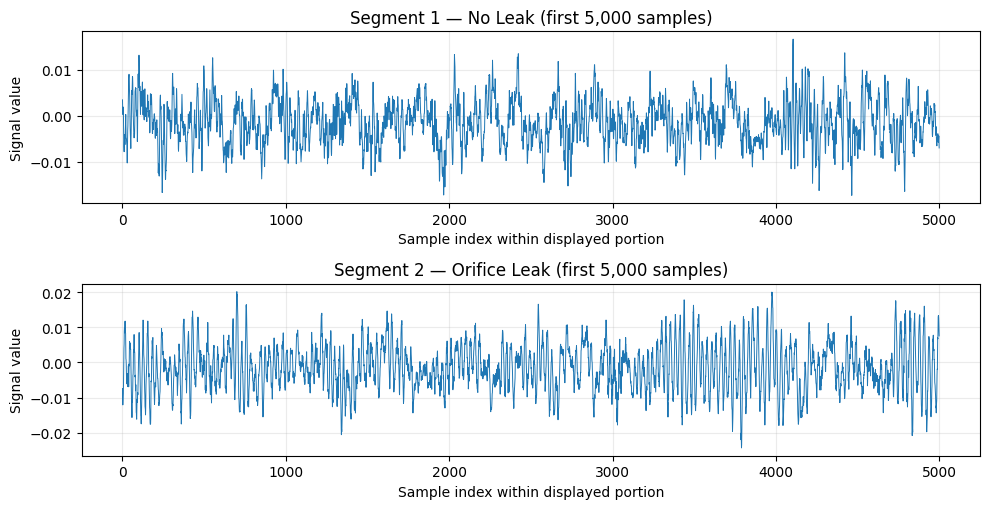

In [11]:
df["segment_id"] = df["label"].ne(df["label"].shift()).cumsum()

segments = (
    df.groupby("segment_id", sort=True)
      .agg(
          label=("label", "first"),
          n_samples=("Value", "size"),
          sample_start=("Sample", "first"),
          sample_end=("Sample", "last"),
          value_min=("Value", "min"),
          value_max=("Value", "max"),
      )
      .reset_index()
)
segments["class_name"] = segments["label"].map(LABEL_NAMES)
display(segments)

print(f"Contiguous labelled segments: {len(segments)}")
if segments["label"].nunique() < 2:
    raise ValueError("Both classes are required for comparative analysis.")

# Plot a small portion of each segment to inspect signal behaviour.
fig, axes = plt.subplots(len(segments), 1, figsize=(10, 2.6 * len(segments)), squeeze=False)
for ax, (_, seg) in zip(axes[:, 0], segments.iterrows()):
    part = df.loc[df["segment_id"] == seg["segment_id"]].head(5000)
    ax.plot(np.arange(len(part)), part["Value"].to_numpy(), linewidth=0.7)
    ax.set_title(f"Segment {int(seg['segment_id'])} — {seg['class_name']} (first {len(part):,} samples)")
    ax.set_xlabel("Sample index within displayed portion")
    ax.set_ylabel("Signal value")
    ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_1_signal_segments.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Window-Based Feature Extraction

In this step, I divide each continuous accelerometer signal segment into fixed-size, non-overlapping windows and extract statistical features from each window. I set the window size to 25,600 samples to obtain consistent signal segments for subsequent analysis. Each window retains the label of its original segment, ensuring that the extracted features remain associated with the corresponding leakage condition.

For every window, I calculate the following nine statistical features:

1. **Mean:** Represents the average signal amplitude.
2. **Standard deviation:** Measures the variability of the signal amplitude.
3. **Root mean square (RMS):** Quantifies the overall signal magnitude.
4. **Centered RMS:** Measures the signal magnitude after subtracting the window mean.
5. **Peak-to-peak amplitude:** Represents the difference between the maximum and minimum signal values.
6. **Absolute peak:** Identifies the maximum absolute signal amplitude.
7. **Crest factor:** Measures the ratio of absolute peak amplitude to RMS and indicates the prominence of signal peaks.
8. **Skewness:** Describes the asymmetry of the signal-value distribution.
9. **Excess kurtosis:** Characterizes the tail heaviness of the signal distribution and its tendency to exhibit extreme values.

I process each segment independently so that no window crosses a transition between different class labels. For each extracted window, I also record its segment ID, window ID, class label, starting and ending sample coordinates, and number of samples.

After feature extraction, I combine the results into a structured DataFrame named `features_df`. I check that at least one complete window has been generated, save the feature table as `leak_window_features.csv`, and display the number of extracted windows for each segment and leakage class.

This step converts the raw accelerometer measurements into a structured feature dataset that can be used for exploratory analysis and machine-learning classification.

In [12]:
def extract_window_features(signal):
    x = np.asarray(signal, dtype=np.float64)
    centered = x - x.mean()
    rms_raw = np.sqrt(np.mean(x ** 2))
    rms_centered = np.sqrt(np.mean(centered ** 2))
    peak = np.max(np.abs(x))

    return {
        "mean": float(np.mean(x)),
        "std": float(np.std(x, ddof=1)) if len(x) > 1 else 0.0,
        "rms": float(rms_raw),
        "centered_rms": float(rms_centered),
        "peak_to_peak": float(np.ptp(x)),
        "absolute_peak": float(peak),
        "crest_factor": float(peak / rms_raw) if rms_raw > 0 else 0.0,
        "skewness": float(skew(x, bias=False)) if len(x) > 2 else 0.0,
        "kurtosis_excess": float(kurtosis(x, fisher=True, bias=False)) if len(x) > 3 else 0.0,
    }

feature_rows = []
for _, seg in segments.iterrows():
    segment = df.loc[df["segment_id"] == seg["segment_id"], ["Sample", "Value", "label"]]
    values = segment["Value"].to_numpy(dtype=np.float64)
    n_full = len(values) // WINDOW_SIZE

    for window_idx in range(n_full):
        start = window_idx * WINDOW_SIZE
        stop = start + WINDOW_SIZE
        row = extract_window_features(values[start:stop])
        row.update({
            "segment_id": int(seg["segment_id"]),
            "window_id": int(window_idx),
            "label": int(seg["label"]),
            "class_name": LABEL_NAMES[int(seg["label"])],
            "sample_start": float(segment["Sample"].iloc[start]),
            "sample_end": float(segment["Sample"].iloc[stop - 1]),
            "n_samples": WINDOW_SIZE,
        })
        feature_rows.append(row)

features_df = pd.DataFrame(feature_rows)
if features_df.empty:
    raise ValueError("No complete windows were produced. Reduce WINDOW_SIZE or check the input.")

feature_path = OUTPUT_DIR / "leak_window_features.csv"
features_df.to_csv(feature_path, index=False)

print(f"Feature table: {features_df.shape[0]} windows × {features_df.shape[1]} columns")
print("\nWindows per segment:")
display(features_df.groupby(["segment_id", "class_name"]).size().rename("n_windows").reset_index())
print(f"Saved: {feature_path}")
display(features_df.head())

Feature table: 70 windows × 16 columns

Windows per segment:


,segment_id,class_name,n_windows
0,1,No Leak,35
1,2,Orifice Leak,35


Saved: /content/leak_analysis_outputs/leak_window_features.csv


,mean,std,rms,centered_rms,peak_to_peak,absolute_peak,crest_factor,skewness,kurtosis_excess,segment_id,window_id,label,class_name,sample_start,sample_end,n_samples
0,-0.001433,0.004770,0.004981,0.004770,0.039519,0.022105,4.438159,-0.036564,0.160885,1,0,0,No Leak,0.0,0.999961,25600
1,-0.001281,0.004574,0.004750,0.004574,0.033058,0.018174,3.825826,-0.018008,-0.063016,1,1,0,No Leak,1.0,1.999961,25600
2,-0.001118,0.004451,0.004589,0.004451,0.038778,0.020312,4.426305,0.000128,0.266140,1,2,0,No Leak,2.0,2.999961,25600
3,-0.001012,0.004839,0.004944,0.004839,0.035016,0.017695,3.579009,0.048611,-0.047109,1,3,0,No Leak,3.0,3.999961,25600
4,-0.000949,0.004781,0.004874,0.004781,0.041179,0.022277,4.570484,0.048137,0.101858,1,4,0,No Leak,4.0,4.999961,25600


## 4. Descriptive Statistical Analysis

In this step, I group the extracted features by leakage condition and calculate the mean, standard deviation, median, minimum, and maximum for each feature. This helps me compare signal characteristics between no-leak and orifice-leak conditions.

I display the summary table and save it as `table_1_descriptive_statistics.csv` for further analysis and reporting.

In [13]:
feature_cols = [
    "mean", "std", "rms", "centered_rms", "peak_to_peak",
    "absolute_peak", "crest_factor", "skewness", "kurtosis_excess"
]

summary = (
    features_df.groupby("class_name")[feature_cols]
    .agg(["mean", "std", "median", "min", "max"])
    .round(6)
)
display(summary)
summary.to_csv(OUTPUT_DIR / "table_1_descriptive_statistics.csv")

mean                                               std  \
                  mean       std    median       min       max      mean   
class_name                                                                 
No Leak      -0.000438  0.000365 -0.000316 -0.001433 -0.000078  0.004735   
Orifice Leak -0.001261  0.000302 -0.001313 -0.001677 -0.000700  0.006443   

                                                      ...  skewness            \
                   std    median       min       max  ...      mean       std   
class_name                                            ...                       
No Leak       0.000123  0.004769  0.004451  0.004935  ...  0.000227  0.046800   
Orifice Leak  0.000160  0.006428  0.006129  0.006738  ... -0.004088  0.046763   

                                           kurtosis_excess            \
                median       min       max            mean       std   
class_name                                                             
No Leak       0.009747 -0.099794  0.118724        0.055301  0.098725   
Orifice Leak -0.012460 -0.088254  0.094930        0.026858  0.080728   

                                            
                median       min       max  
class_name                                  
No Leak       0.054748 -0.095874  0.266140  
Orifice Leak  0.012897 -0.091472  0.170187  

[2 rows x 45 columns]

## 5. Feature Distribution Visualization

In this step, I use boxplots to compare the distributions of four key features—RMS, peak-to-peak amplitude, crest factor, and excess kurtosis—between no-leak and orifice-leak conditions. These plots help me identify differences in signal magnitude, variability, and distribution characteristics. I save the figure at 300 DPI for research reporting.

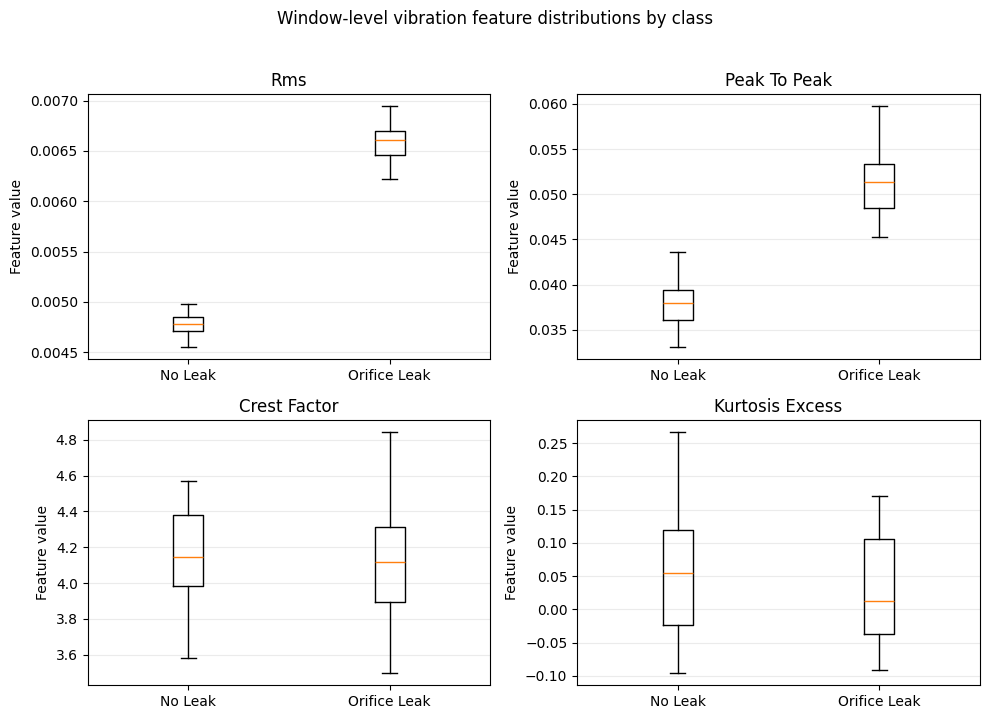

In [14]:
plot_features = ["rms", "peak_to_peak", "crest_factor", "kurtosis_excess"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for ax, feature in zip(axes.flat, plot_features):
    groups = [
        features_df.loc[features_df["label"] == label, feature].dropna().to_numpy()
        for label in [0, 1]
    ]
    ax.boxplot(groups, tick_labels=[LABEL_NAMES[0], LABEL_NAMES[1]], showfliers=False)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_ylabel("Feature value")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Window-level vibration feature distributions by class", y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figure_2_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Random Forest Classification and Model Evaluation

In this step, I train a Random Forest classifier to distinguish between no-leak and orifice-leak conditions using the extracted signal features. I perform five-fold cross-validation on the training data and evaluate the model separately on the training, validation, and test sets using accuracy, precision, recall, F1-score, and ROC-AUC.

I also generate a test-set confusion matrix, ROC curve, actual-versus-predicted label plot, and feature-importance plot. Finally, I save the evaluation metrics, test predictions, figures, and feature-importance results for reproducibility and research reporting.

In [18]:
# RANDOM FOREST LEAK DETECTION: COMPLETE EVALUATION PIPELINE
# 5-Fold CV + Training + Validation + Final Test

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [19]:
# 1. CONFIGURATION

RANDOM_STATE = 42

model_features = [
    "std",
    "rms",
    "peak_to_peak",
    "absolute_peak",
    "crest_factor",
    "skewness",
    "kurtosis_excess"
]

class_names = {
    0: "No Leak",
    1: "Orifice Leak"
}

In [20]:
# 2. Data Preparation

X = features_df[model_features].copy()
y = features_df["label"].astype(int).copy()

X = X.replace([np.inf, -np.inf], np.nan)

if X.isna().any().any():
    raise ValueError(
        "Missing or infinite feature values detected. "
        "Resolve them before model training."
    )

if y.nunique() != 2:
    raise ValueError("This evaluation requires exactly two classes.")

if set(y.unique()) != {0, 1}:
    raise ValueError("Expected binary labels 0 and 1.")

print("=" * 65)
print("DATASET SUMMARY")
print("=" * 65)
print("Total windows:", len(X))
print("Features:", len(model_features))
print("\nClass distribution:")
print(y.map(class_names).value_counts())

DATASET SUMMARY
Total windows: 70
Features: 7

Class distribution:
label
No Leak         35
Orifice Leak    35
Name: count, dtype: int64


In [21]:
# 3. TRAIN / VALIDATION / TEST SPLIT
#    70% train, 15% validation, 15% test

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=RANDOM_STATE
)

# 15% of the original dataset for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.15 / 0.85,
    stratify=y_trainval,
    random_state=RANDOM_STATE
)

print("\n" + "=" * 65)
print("DATA SPLIT")
print("=" * 65)

for name, X_part, y_part in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(
        f"{name:12s}: {len(X_part):6d} windows "
        f"({len(X_part) / len(X) * 100:.2f}%)"
    )
    print("  Class counts:", y_part.value_counts().sort_index().to_dict())


DATA SPLIT
Training    :     48 windows (68.57%)
  Class counts: {0: 24, 1: 24}
Validation  :     11 windows (15.71%)
  Class counts: {0: 5, 1: 6}
Test        :     11 windows (15.71%)
  Class counts: {0: 6, 1: 5}


In [22]:
# 4. cross validation on training dataset

rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

cv_table = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1": cv_results["test_f1"],
    "ROC_AUC": cv_results["test_roc_auc"]
})

print("\n" + "=" * 65)
print("FIVE-FOLD CROSS-VALIDATION: TRAINING PARTITION")
print("=" * 65)

print(cv_table.round(4).to_string(index=False))

cv_summary = pd.DataFrame({
    "Metric": scoring.keys(),
    "Mean": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Std": [
        cv_results[f"test_{metric}"].std(ddof=1)
        for metric in scoring
    ]
})

print("\nCross-validation summary (mean ± standard deviation):")
print(cv_summary.round(4).to_string(index=False))

cv_table.to_csv(
    OUTPUT_DIR / "table_3_five_fold_cv.csv",
    index=False
)
cv_summary.to_csv(
    OUTPUT_DIR / "table_4_cv_summary.csv",
    index=False
)


FIVE-FOLD CROSS-VALIDATION: TRAINING PARTITION
 Fold  Accuracy  Precision  Recall  F1  ROC_AUC
    1       1.0        1.0     1.0 1.0      1.0
    2       1.0        1.0     1.0 1.0      1.0
    3       1.0        1.0     1.0 1.0      1.0
    4       1.0        1.0     1.0 1.0      1.0
    5       1.0        1.0     1.0 1.0      1.0

Cross-validation summary (mean ± standard deviation):
   Metric  Mean  Std
 accuracy   1.0  0.0
precision   1.0  0.0
   recall   1.0  0.0
       f1   1.0  0.0
  roc_auc   1.0  0.0


In [23]:
# 5. TRAIN FINAL MODEL ON TRAINING PARTITION

rf.fit(X_train, y_train)

print("\nFinal Random Forest fitted on the training partition.")


Final Random Forest fitted on the training partition.


In [24]:
# 6. EVALUATE TRAINING, VALIDATION AND TEST SETS


def calculate_metrics(model, X_part, y_part, split_name):
    predictions = model.predict(X_part)
    probabilities = model.predict_proba(X_part)[:, 1]

    return {
        "Dataset": split_name,
        "N": len(y_part),
        "Accuracy": accuracy_score(y_part, predictions),
        "Precision": precision_score(
            y_part, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_part, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_part, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_part, probabilities)
    }

metrics_table = pd.DataFrame([
    calculate_metrics(rf, X_train, y_train, "Training"),
    calculate_metrics(rf, X_val, y_val, "Validation"),
    calculate_metrics(rf, X_test, y_test, "Test")
])

print("\n" + "=" * 65)
print("TRAINING / VALIDATION / TEST METRICS")
print("=" * 65)
print(metrics_table.round(4).to_string(index=False))

metrics_table.to_csv(
    OUTPUT_DIR / "table_5_model_metrics.csv",
    index=False
)

# Detailed report for the untouched test partition
y_test_pred = rf.predict(X_test)
y_test_prob = rf.predict_proba(X_test)[:, 1]

print("\nTEST SET CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["No Leak", "Orifice Leak"],
        digits=4,
        zero_division=0
    )
)



TRAINING / VALIDATION / TEST METRICS
   Dataset  N  Accuracy  Precision  Recall  F1  ROC_AUC
  Training 48       1.0        1.0     1.0 1.0      1.0
Validation 11       1.0        1.0     1.0 1.0      1.0
      Test 11       1.0        1.0     1.0 1.0      1.0

TEST SET CLASSIFICATION REPORT
              precision    recall  f1-score   support

     No Leak     1.0000    1.0000    1.0000         6
Orifice Leak     1.0000    1.0000    1.0000         5

    accuracy                         1.0000        11
   macro avg     1.0000    1.0000    1.0000        11
weighted avg     1.0000    1.0000    1.0000        11



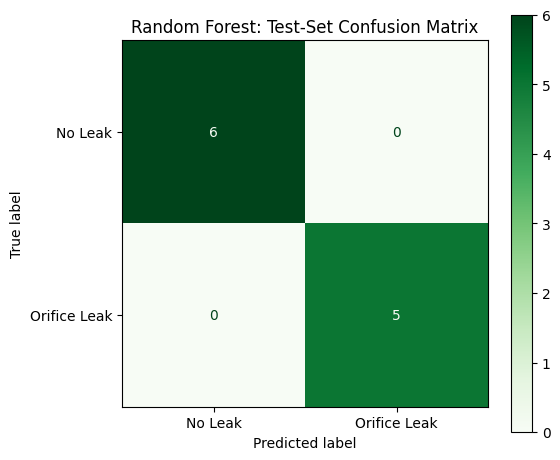

In [30]:
# 7. Confusion Matrix on Test Dataset

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["No Leak", "Orifice Leak"],
    cmap="Greens",
    values_format="d",
    ax=ax
)

ax.set_title("Random Forest: Test-Set Confusion Matrix")
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_4_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Save the numerical confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

pd.DataFrame(
    cm,
    index=["Actual_No_Leak", "Actual_Orifice_Leak"],
    columns=["Predicted_No_Leak", "Predicted_Orifice_Leak"]
).to_csv(OUTPUT_DIR / "table_6_test_confusion_matrix.csv")

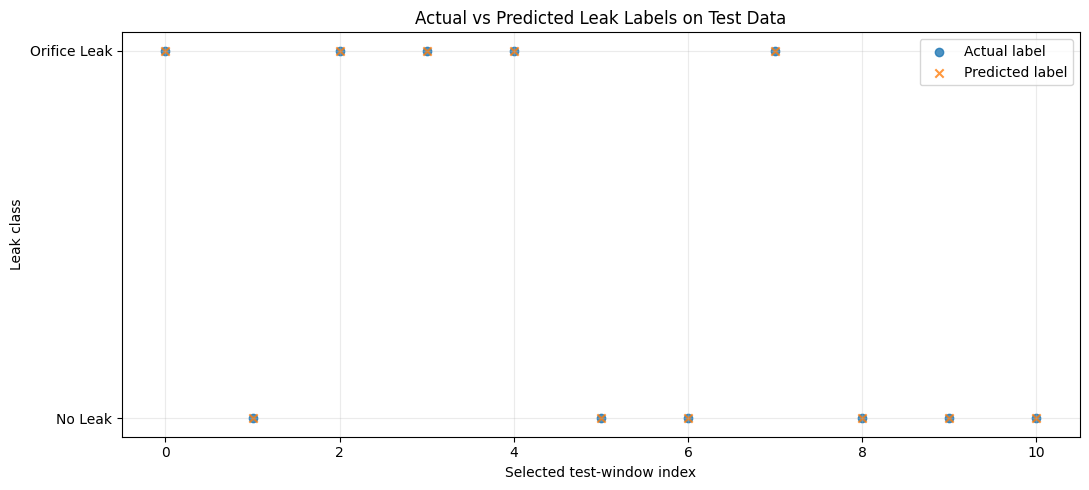

In [26]:
# 8. ACTUAL VS PREDICTED LABELS ON TEST DATA

# Display a reproducible sample if the test set is very large.
n_plot = min(500, len(y_test))

rng = np.random.default_rng(RANDOM_STATE)
selected = np.sort(
    rng.choice(len(y_test), size=n_plot, replace=False)
)

actual_sample = y_test.to_numpy()[selected]
predicted_sample = y_test_pred[selected]

fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    np.arange(n_plot),
    actual_sample,
    label="Actual label",
    marker="o",
    alpha=0.8
)

ax.scatter(
    np.arange(n_plot),
    predicted_sample,
    label="Predicted label",
    marker="x",
    alpha=0.8
)

ax.set_yticks([0, 1], labels=["No Leak", "Orifice Leak"])
ax.set_xlabel("Selected test-window index")
ax.set_ylabel("Leak class")
ax.set_title("Actual vs Predicted Leak Labels on Test Data")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_5_actual_vs_predicted_test.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

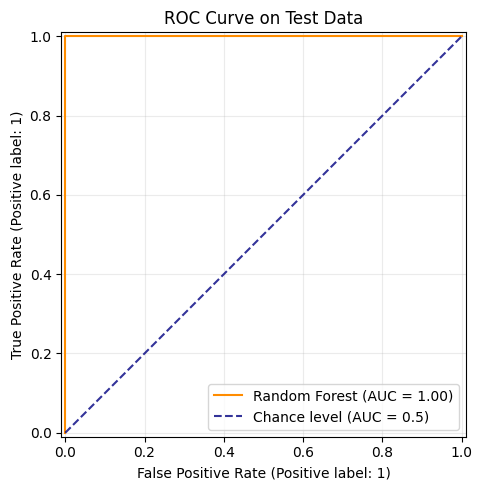

In [32]:
# 9. ROC CURVE ON TEST DATA

fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob,
    name="Random Forest",
    color="darkorange",
    ax=ax
)

# Style the plot
ax.set_title("ROC Curve on Test Data")
ax.grid(alpha=0.25)

# Explicitly draw and style the diagonal reference line
ax.plot(
    [0, 1],
    [0, 1],
    color="navy",
    linestyle="--",
    alpha=0.8,
    label="Chance level (AUC = 0.5)"
)

# Update legend to include the chance line
ax.legend(loc="lower right")

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_6_test_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


FEATURE IMPORTANCE
        Feature  Importance
            std     0.27366
            rms     0.26186
   peak_to_peak     0.25748
  absolute_peak     0.18122
   crest_factor     0.01064
kurtosis_excess     0.00974
       skewness     0.00540


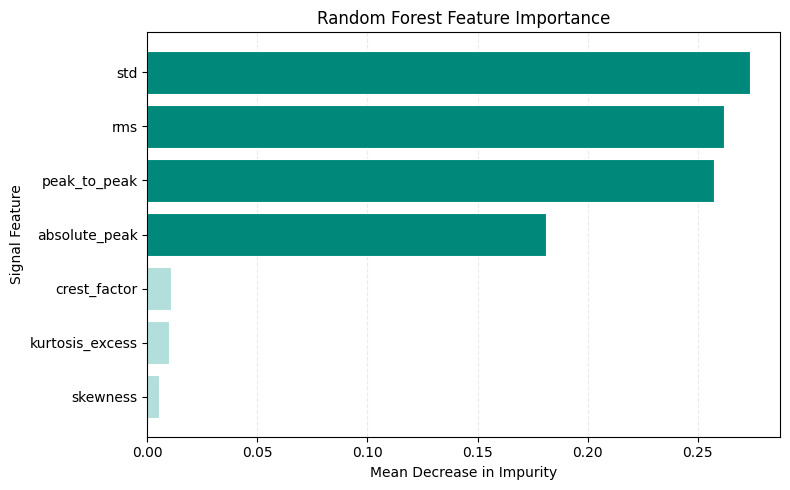

In [33]:
# 10. FEATURE IMPORTANCE

importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": rf.feature_importances_
}).sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

print("\nFEATURE IMPORTANCE")
print(importance.round(5).to_string(index=False))

importance.to_csv(
    OUTPUT_DIR / "table_7_feature_importance.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 5))

plot_data = importance.sort_values("Importance", ascending=True)

# Use a teal gradient to distinguish feature importance
colors = [
    "#B2DFDB" if value < plot_data["Importance"].quantile(0.5)
    else "#00897B"
    for value in plot_data["Importance"]
]

ax.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    color=colors,
    edgecolor="white",
    linewidth=0.8
)

ax.set_xlabel("Mean Decrease in Impurity")
ax.set_ylabel("Signal Feature")
ax.set_title("Random Forest Feature Importance")

ax.grid(axis="x", alpha=0.25, linestyle="--")
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "figure_7_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
# 11. EXPORT TEST PREDICTIONS

test_predictions = X_test.copy()
test_predictions["Actual_Label"] = y_test
test_predictions["Predicted_Label"] = y_test_pred
test_predictions["Predicted_Leak_Probability"] = y_test_prob
test_predictions["Actual_Class"] = (
    test_predictions["Actual_Label"].map(class_names)
)
test_predictions["Predicted_Class"] = (
    test_predictions["Predicted_Label"].map(class_names)
)

test_predictions.to_csv(
    OUTPUT_DIR / "table_8_test_predictions.csv",
    index=False
)

print("\n" + "=" * 65)
print("WORKFLOW COMPLETED")
print("=" * 65)
print("All tables and figures saved to:", OUTPUT_DIR)
print(
    "Important: results from random window splits are exploratory "
    "and do not establish generalization to unseen recordings."
)



WORKFLOW COMPLETED
All tables and figures saved to: /content/leak_analysis_outputs
Important: results from random window splits are exploratory and do not establish generalization to unseen recordings.
